This code is authored by Raghav Y.
Contains the codes needed to see disparity in the edge and node dataset as well as a visulaizer for ingredient frequency over different cuisines.

In [ ]:
import pandas as pd
nodes_df = pd.read_csv('nodes_8.0.csv')
edges_df = pd.read_csv('edges_clean_2.csv')

correct_nodes = set(edges_df['Source']).union(set(edges_df['Target']))
print(correct_nodes)
cleaned_nodes = nodes_df[nodes_df['Id'].isin(correct_nodes)]

cleaned_nodes.to_csv('cleaned_nodes_2.csv', index=False)

{'D03115', 'D02072', 'D02512', 'fish fillet', 'D02666', 'D03590', 'roti', 'byadagi dried chillies', 'tender mango', 'D03776', 'D04821', 'D01039', 'star anise', 'curry', 'malwani masala', 'D00222', 'D03043', 'D02486', 'baby corn', 'D05782', 'D00501', 'D05337', 'D00108', 'D03516', 'D01031', 'kidney beans', 'D01268', 'D01940', 'D03717', 'D04712', 'mixed sprouts', 'D00757', 'D01988', 'D00713', 'D03570', 'D00351', 'D01536', 'bottle gourd', 'jam', 'D04945', 'D05290', 'D02010', 'D00403', 'D02889', 'D04271', 'ssp asafoetida', 'D01599', 'D05549', 'D00592', 'agar agar', 'D05338', 'beetroot', 'D01447', 'champagne', 'D05522', 'D03940', 'lavang', 'D05403', 'D02834', 'D01470', 'D03907', 'D01137', 'D04356', 'D04405', 'D00219', 'D02545', 'tindora', 'D05528', 'D03613', 'D00264', 'D05266', 'D01863', 'D03052', 'D05919', 'D03533', 'black grapes', 'gm mutton', 'D01735', 'mango pulp', 'D02279', 'D05187', 'D04344', 'D01582', 'D02440', 'D04676', 'D04174', 'D04482', 'D04752', 'D01143', 'D02571', 'D01534', 'D01

In [7]:
missing_nodes = set(edges_df['Source']).union(set(edges_df['Target'])) - set(nodes_df['Id'])

print("Missing nodes:", len(missing_nodes))
print(missing_nodes)

Missing nodes: 0
set()


In [20]:
import pandas as pd

# Load datasets
nodes_df = pd.read_csv('nodes_8.0.csv')
edges_df = pd.read_csv('edges_5.0.csv')

# Find all nodes referenced in edges
correct_nodes = set(edges_df['Source']).union(
    set(edges_df['Target'])
)

# Find missing nodes
missing_nodes = correct_nodes - set(nodes_df['Id'])

print("Total unique nodes in edges:", len(correct_nodes))
print("Missing nodes:", len(missing_nodes))
print(missing_nodes)

# Keep only nodes that appear in edges
cleaned_nodes = nodes_df[
    nodes_df['Id'].isin(correct_nodes)
].copy()

# Save cleaned dataset
cleaned_nodes.to_csv('cleaned_nodes_2.csv', index=False)

print("Original nodes:", len(nodes_df))
print("Cleaned nodes:", len(cleaned_nodes))

Total unique nodes in edges: 4967
Missing nodes: 0
set()
Original nodes: 4967
Cleaned nodes: 4967



Ingredient: salt
                          Ingredient_Dishes  Total_Dishes  Prevalence (%)
Cuisine                                                                  
Jharkhand                                 2             2          100.00
South Karnataka                           9             9          100.00
Nagaland                                  3             3          100.00
Kongunadu                                 3             3          100.00
Kashmiri                                 42            44           95.45
North East India Recipes                 16            17           94.12
Mangalorean                              41            45           91.11
Tamil Nadu                              119           133           89.47
Parsi Recipes                            32            36           88.89
Awadhi                                   29            33           87.88
South Indian Recipes                    487           558           87.28
Udupi               

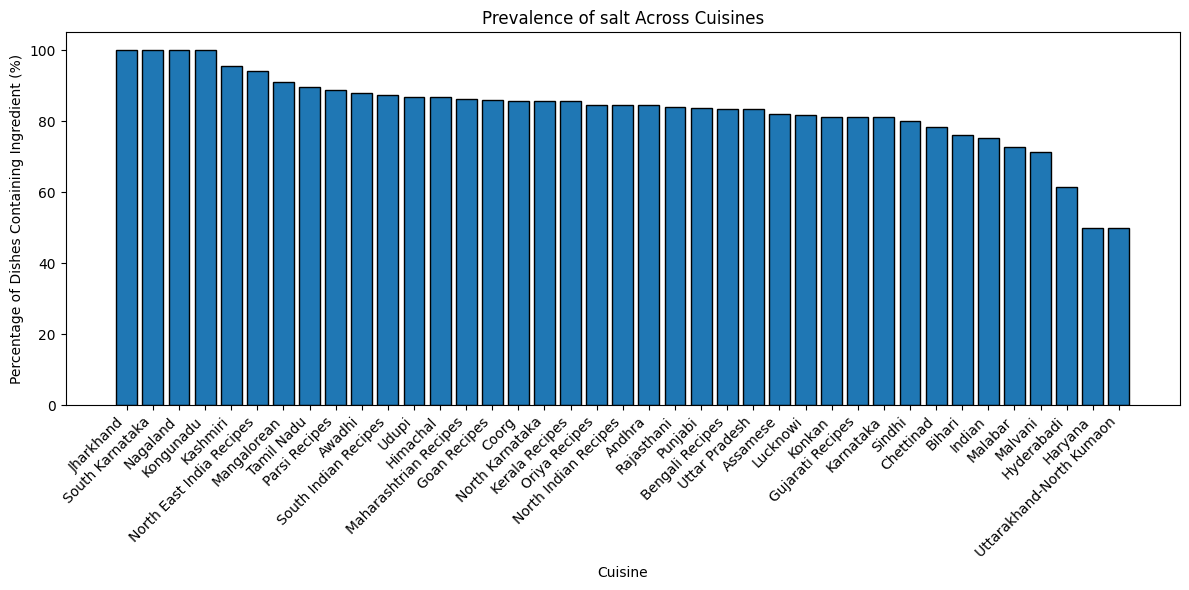

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

#Load datasets
nodes_df = pd.read_csv('nodes_8.0.csv')
edges_df = pd.read_csv('edges_clean_2.csv')

#Separate recipes and ingredients
recipes = nodes_df[nodes_df['Type'] == 'Recipe'].copy()
ingredients = nodes_df[nodes_df['Type'] != 'Recipe'].copy()

# Take ingredient input
ingredient_name = input("Enter ingredient name: ").strip().lower()

matching_ingredients = ingredients[
    (ingredients['Label'].astype(str).str.lower() == ingredient_name) |
    (ingredients['Id'].astype(str).str.lower() == ingredient_name)
]

if matching_ingredients.empty:
    print("Ingredient not found!")

else:
    ingredient_ids = set(matching_ingredients['Id'])

    #Find recipes connected to the ingredient
    connected_recipes = set()

    for source, target in edges_df[['Source', 'Target']].itertuples(
        index=False, name=None
    ):
        if source in ingredient_ids:
            connected_recipes.add(target)
        elif target in ingredient_ids:
            connected_recipes.add(source)

    # Retain only recipe IDs
    connected_recipes &= set(recipes['Id'])

    #Total number of dishes in each cuisine
    total_dishes = recipes.groupby('Cuisine')['Id'].nunique()

    #Number of dishes containing ingredient in each cuisine
    ingredient_dishes = recipes[
        recipes['Id'].isin(connected_recipes)
    ]

    ingredient_counts = ingredient_dishes.groupby('Cuisine')['Id'].nunique()

    # Combine and Normalize
    results = pd.DataFrame({
        'Ingredient_Dishes': ingredient_counts,
        'Total_Dishes': total_dishes
    }).fillna(0)

    results['Prevalence (%)'] = (
        results['Ingredient_Dishes'] /
        results['Total_Dishes']
    ) * 100

    results = results.sort_values(
        'Prevalence (%)', ascending=False
    )

    print(f"\nIngredient: {ingredient_name}")
    print(results.round(2).to_string())

    plt.figure(figsize=(12, 6))

    plt.bar(
        results.index.astype(str),
        results['Prevalence (%)'],
        edgecolor='black'
    )

    plt.title(f'Prevalence of {ingredient_name} Across Cuisines')
    plt.xlabel('Cuisine')
    plt.ylabel('Percentage of Dishes Containing Ingredient (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
